# Human white adipose tissue snRNA-seq (CELLxGENE): cell types, an artefact cluster, and depot differences in adipocytes

Dataset: CELLxGENE collection [6b701826-37bb-4356-9792-ff41fc4c3161](https://cellxgene.cziscience.com/collections/6b701826-37bb-4356-9792-ff41fc4c3161)
(*Single-Nucleus Analysis of Human White Adipose Tissue Reveals Adipocyte Subsets with Distinct Metabolic Profiles*;
65,668 nuclei, 19 donors, visceral and subcutaneous abdominal WAT, 10x 3' v3).

All logic lives in `src/wat_pipeline.py`; this notebook calls it step by step and records the biological reading of each result.
Persistent files are written to `WAT_DATA_DIR` (default `~/adipose_cxg/data`) and re-used if they already exist.

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("NUMBA_CACHE_DIR", str(Path(".numba_cache").resolve()))
sys.path.insert(0, str(Path("..").resolve() / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import wat_pipeline as wp

RESULTS = Path("..") / "results"; RESULTS.mkdir(exist_ok=True)
print("data dir:", wp.DATA_DIR)

data dir: /Users/anthropic/adipose_cxg/data


## 1. Download (verify-if-exists) and load

In [2]:
path = wp.fetch_dataset()
adata = wp.load_dataset(path)
adata

AnnData object with n_obs × n_vars = 65668 × 35476
    obs: 'reference_genome', 'gene_annotation_version', 'alignment_software', 'intronic_reads_counted', 'donor_id', 'self_reported_ethnicity_ontology_term_id', 'donor_living_at_sample_collection', 'sample_id', 'sample_preservation_method', 'tissue_ontology_term_id', 'development_stage_ontology_term_id', 'sample_collection_method', 'tissue_source', 'donor_BMI_at_collection', 'tissue_type', 'suspension_derivation_process', 'suspension_dissociation_reagent', 'suspension_dissociation_time', 'suspension_type', 'library_id', 'assay_ontology_term_id', 'sequenced_fragment', 'cell_number_loaded', 'institute', 'is_primary_data', 'cell_type_ontology_term_id', 'author_cell_type', 'disease_ontology_term_id', 'sex_ontology_term_id', 'nCount_log_10k_norm', 'nFeature_log_10k_norm', 'percent.mt', 'percent.ribo', 'seurat_clusters', 'broadCellType', 'origin', 'HbA1c', 'BMI', 'T2D', 'Race_Ethnicity', 'predicted.id', 'predicted.celltype.score', 'mapping.sc

## 2. How many nuclei, and is the data normalised?
`X` is log1p of counts scaled to 10,000 per nucleus (the expm1 row sums are ~10,000); raw integer UMI counts are kept in `adata.raw.X`.

In [3]:
print(f"{adata.n_obs:,} nuclei x {adata.n_vars:,} genes")
wp.normalisation_report(adata)

65,668 nuclei x 35,476 genes


,X_rowsum,expm1_X_rowsum,raw_UMI
TATTTCGGTTCGGTTA-1_03_SQ,3626.6,9851.1,54848.0
AAAGTCCCAGTGGTGA-1_03_SQ,3977.9,9959.7,43184.0
TCCTGCAGTTTGGCTA-1_03_SQ,3509.3,9951.7,41155.0
TTTGATCTCTCCTGCA-1_03_SQ,4249.2,9912.4,38628.0
CTACCCATCATCAGTG-1_03_SQ,3868.3,9927.2,37341.0


## 3. UMAP by cell type and by ADIPOQ

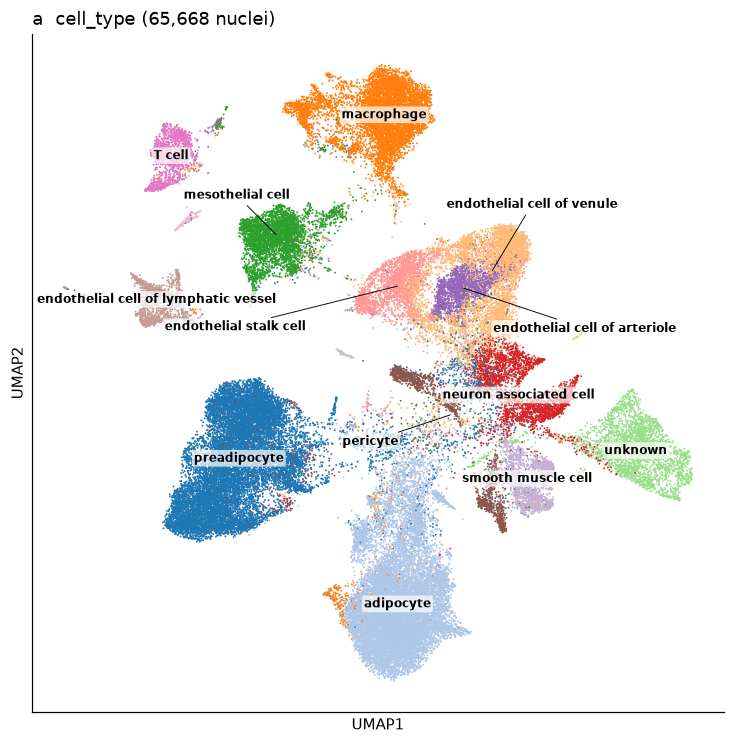

In [4]:
fig = wp.plot_umap_celltype(adata)[0]
fig.savefig(RESULTS / "umap_cell_type.png", dpi=150, bbox_inches="tight"); plt.show()

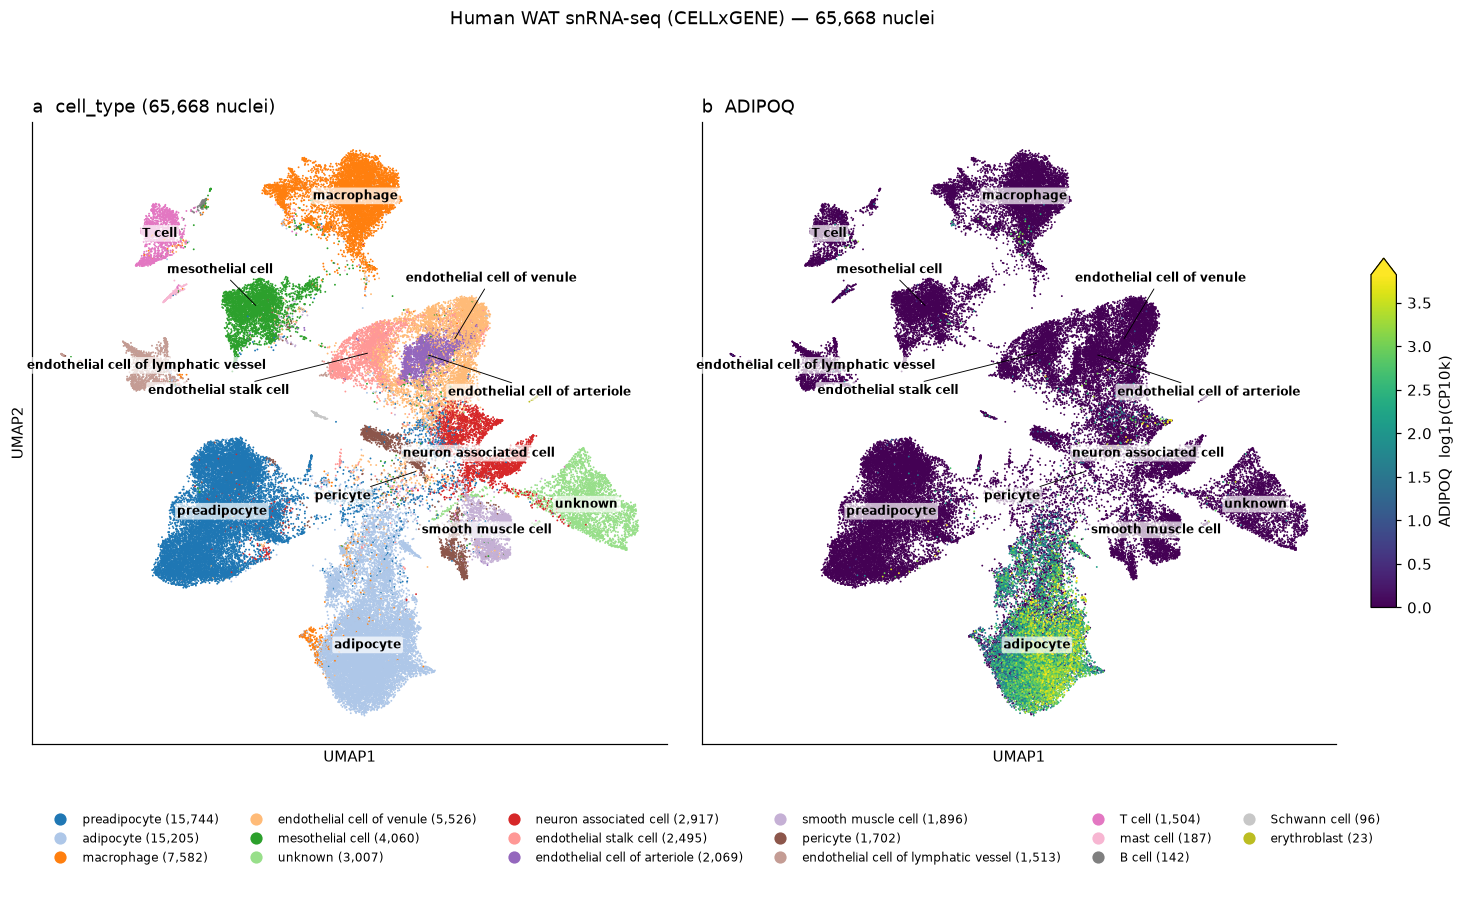

,frac_detected,mean_log1p
cell_type,,
adipocyte,0.720026,1.474006
neuron associated cell,0.036682,0.081138
Schwann cell,0.031250,0.054970
macrophage,0.027697,0.048388
endothelial cell of venule,0.016468,0.031671
endothelial cell of lymphatic vessel,0.014541,0.023000


In [5]:
fig = wp.plot_umap_celltype_and_gene(adata, "ADIPOQ")
fig.savefig(RESULTS / "umap_cell_type_ADIPOQ.png", dpi=150, bbox_inches="tight"); plt.show()
wp.gene_by_celltype(adata, "ADIPOQ").head(6)

**Reading.** ADIPOQ is restricted to the adipocyte lobe (~70% of adipocyte nuclei) and absent from preadipocytes — a clean terminal-differentiation split.
Expression is graded within the adipocyte cluster, consistent with the adipocyte sub-states described by the authors.

## 4. Sources of batch effects
The finest technical unit is the library (1:1 with sample), nested in donor. Depot is almost completely nested in donor:
only three donors contribute both depots. Donor carries sex, BMI, T2D status and ancestry; three Cell Ranger versions were used.

In [6]:
bo = wp.batch_overview(adata)
print(f"{bo['n_libraries']} libraries = {bo['n_samples']} samples from {bo['n_donors']} donors; paired donors: {bo['paired_donors']}")
print(bo["alignment_software_libraries"].to_string())
bo["donor_x_depot"]

22 libraries = 22 samples from 19 donors; paired donors: ['donor-BLUE', 'donor-GOLD', 'donor-TREE']
alignment_software
Cell Ranger count v5.0.0     1
Cell Ranger count v6.0.1     8
Cell Ranger count v6.0.2    13


tissue,visceral,subcutaneous
donor_id,,
donor-APEX,2475,0
donor-BLUE,3216,3396
donor-BOAT,3374,0
donor-CORK,0,2258
donor-COST,6718,0
donor-DOVE,596,0
donor-DOWN,3945,0
donor-GOLD,5683,676
donor-KEYS,0,3649


## 5. What is the "unknown" cluster? scanpy t-test vs every other cell type, controlling for donor

In [7]:
de_unknown = wp.de_group_vs_each(adata, "unknown")
cons = wp.consensus_markers(de_unknown, "unknown")
de_unknown.to_csv(RESULTS / "DGE_unknown_vs_each_cell_type_donorcentred_ttest.csv", index=False)
cons.to_csv(RESULTS / "DGE_unknown_consensus_up.csv")
n_other = de_unknown["reference"].nunique()
top = cons[cons.n_refs == n_other].head(20)
top

,n_refs,min_log2FC,pct_group,max_pct_ref
names,,,,
PRM1,16,9.650335,0.850349,0.027083
TNP1,16,8.994149,0.829398,0.024340
DYNLT2,16,7.850586,0.790821,0.036107
TUBA3C,16,7.837345,0.815098,0.027768
OAZ3,16,7.696068,0.789491,0.025711
ENSG00000187186,16,7.659534,0.813768,0.029482
PGP,16,7.200073,0.795477,0.067528
C1QTNF4,16,7.151316,0.726305,0.022283
FABP9,16,7.134230,0.709012,0.021940


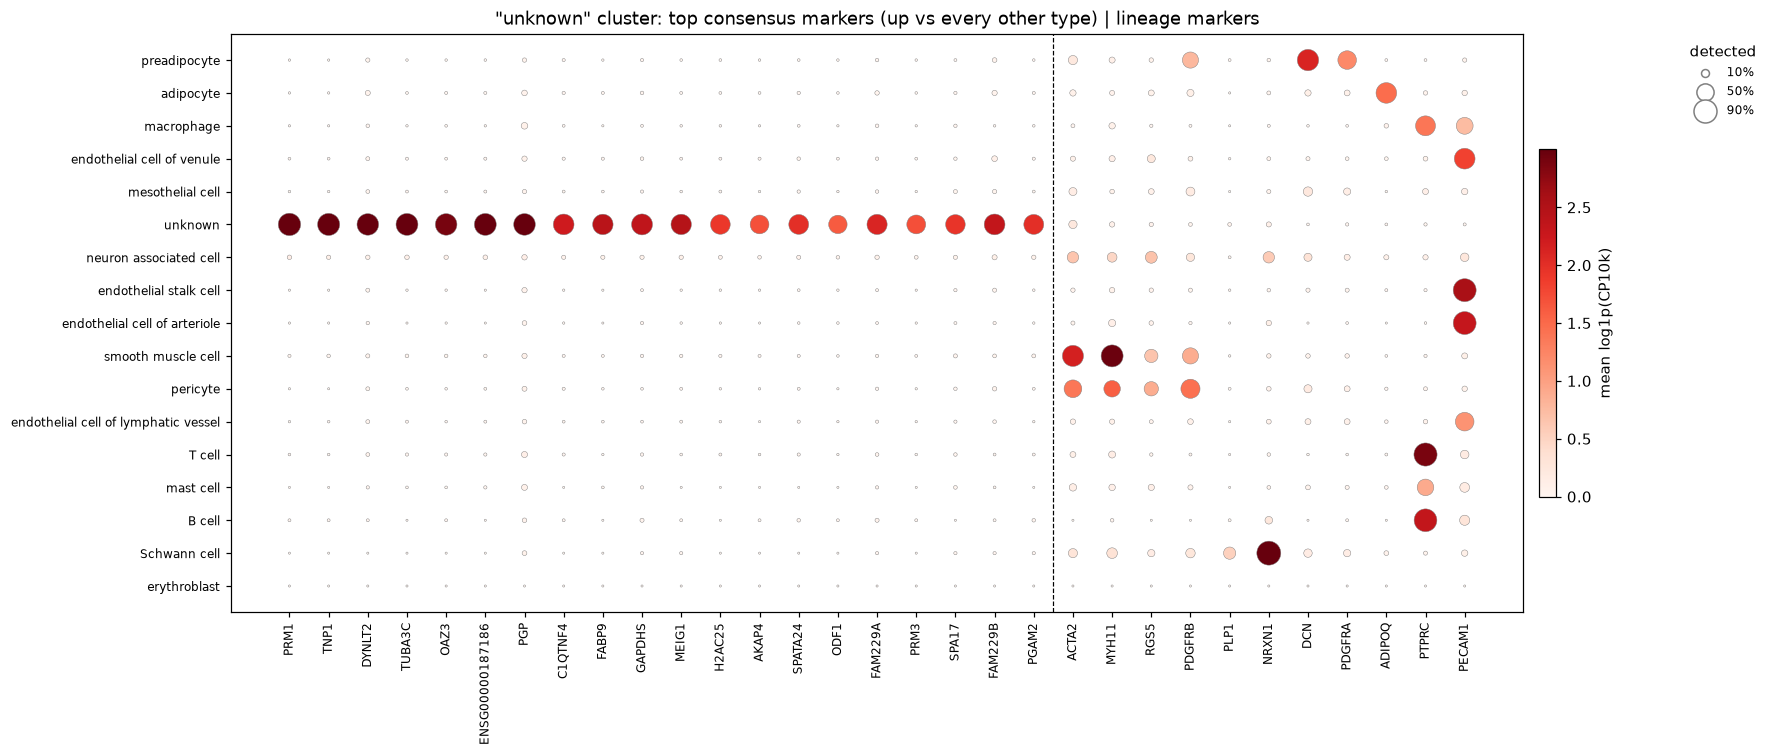

In [8]:
lineage = [g for g in ["ACTA2", "MYH11", "RGS5", "PDGFRB", "PLP1", "NRXN1", "DCN", "PDGFRA", "ADIPOQ", "PTPRC", "PECAM1"]]
fig = wp.dotplot(adata, top.index.tolist() + lineage, split_at=len(top),
                 title='"unknown" cluster: top consensus markers (up vs every other type) | lineage markers')
fig.savefig(RESULTS / "DGE_unknown_markers_dotplot.png", dpi=150, bbox_inches="tight"); plt.show()

In [9]:
qc = wp.qc_summary(adata, "unknown")
print("median UMI (lowest four):\n", qc["median_umi_by_type"].head(4).to_string())
print("\nsex of donors contributing 'unknown' nuclei:\n", qc["sex_fraction"].to_string())
print("\ndepot:\n", qc["depot_counts"].to_string())
print("\nshare of library made up of 'unknown' nuclei (top 5):\n", qc["fraction_of_library"].head(5).to_string())
print("\nauthor label:\n", adata.obs.loc[adata.obs.cell_type == "unknown", "author_cell_type"].value_counts().head(3).to_string())

median UMI (lowest four):
 ct
erythroblast               813.0
unknown                   1384.0
neuron associated cell    1386.0
T cell                    2476.0

sex of donors contributing 'unknown' nuclei:
 sex
female    0.91
male      0.09

depot:
 depot
visceral        2733
subcutaneous     274

share of library made up of 'unknown' nuclei (top 5):
 lib
3df6c15b-fc26-437f-820f-0ec3a771990f    0.17
7f069a69-2f7c-478b-a494-4c5db9d6ae82    0.16
20027346-e846-46db-91c7-0574419aedda    0.13
9bd51e5d-a167-4dfd-8943-51fcf0d38686    0.09
4b9e7151-7395-4b1f-8c9b-2033f6658a54    0.07

author label:
 author_cell_type
PRM1+      2925
Unknown      82
APC2          0


**Reading.** The "unknown" cluster is a late-spermatid gene signature (PRM1, PRM3, TNP1, ODF1, AKAP4, GAPDHS, SPATA24, MEIG1, TUBA3C, ACTL7B)
with no lineage marker of its own; the authors labelled it "PRM1+". It is biologically impossible as sampled — ~90% of the nuclei come from
**female** donors, mostly visceral, concentrated in a few libraries, with the lowest UMI counts after erythroblasts. It is a
contamination/low-quality artefact and is excluded from here on.

## 6. Adipocyte-only object (raw counts + depot/donor/library fields)

In [10]:
adi = wp.extract_adipocytes(adata)
print(wp.ADIPOCYTES, adi.shape, adi.X.dtype)
adi.obs.groupby("depot", observed=True).agg(nuclei=("donor_id", "size"), donors=("donor_id", "nunique"), libraries=("library_id", "nunique"))

/Users/anthropic/adipose_cxg/data/wat_snrna_adipocytes.h5ad (15205, 35476) int32


,nuclei,donors,libraries
depot,,,
visceral,10584,12,12
subcutaneous,4621,10,10


## 7. Visceral vs subcutaneous adipocytes
Depot is nested in donor, so the primary analysis is **pseudobulk per library** (sum raw counts, log2 CPM, Welch t-test, BH),
with the three paired donors used as a sign-concordance check. The cell-level donor-adjusted t-test is shown alongside for comparison only:
nuclei are not independent replicates, so it is anti-conservative.

In [11]:
T = wp.pseudobulk_depot_de(adi)
T.to_csv(RESULTS / "DGE_adipocytes_visceral_vs_subcutaneous.csv", index=False)
sig = T[(T.pb_padj < 0.05) & (T.pb_log2FC_vis_vs_sq.abs() > 1)]
print(f"{T.attrs['n_libraries']} libraries; paired donors {T.attrs['paired_donors']}")
print(f"pseudobulk: {(sig.pb_log2FC_vis_vs_sq > 0).sum()} up visceral, {(sig.pb_log2FC_vis_vs_sq < 0).sum()} up subcutaneous "
      f"(padj<0.05, |log2FC|>1); {(sig.paired_donors_concordant == len(T.attrs['paired_donors'])).mean():.0%} concordant in all paired donors")
print(f"cell-level: {((T.cell_padj < 0.05) & (T.cell_log2FC_vis_vs_sq.abs() > 1)).sum()} hits at the same thresholds")
print("\nup subcutaneous:", sig.sort_values("pb_log2FC_vis_vs_sq").gene.head(12).tolist())
print("up visceral:    ", sig.sort_values("pb_log2FC_vis_vs_sq").gene.tail(12).tolist()[::-1])

22 libraries; paired donors ['donor-BLUE', 'donor-TREE', 'donor-GOLD']
pseudobulk: 57 up visceral, 70 up subcutaneous (padj<0.05, |log2FC|>1); 93% concordant in all paired donors
cell-level: 346 hits at the same thresholds

up subcutaneous: ['NRCAM', 'CRNDE', 'HOXC6', 'SIM1', 'HOXC8', 'NECAB1', 'TBX15', 'COL11A1', 'EMX2OS', 'HOXC9', 'TWIST1', 'GLIPR2']
up visceral:     ['LINC01725', 'MROH7', 'EBF2', 'ACOT11', 'NR2F1', 'ISL1-DT', 'ENOX1', 'ENSG00000285534', 'RXRG', 'ENSG00000286473', 'LINC01798', 'ALDH1L1-AS2']


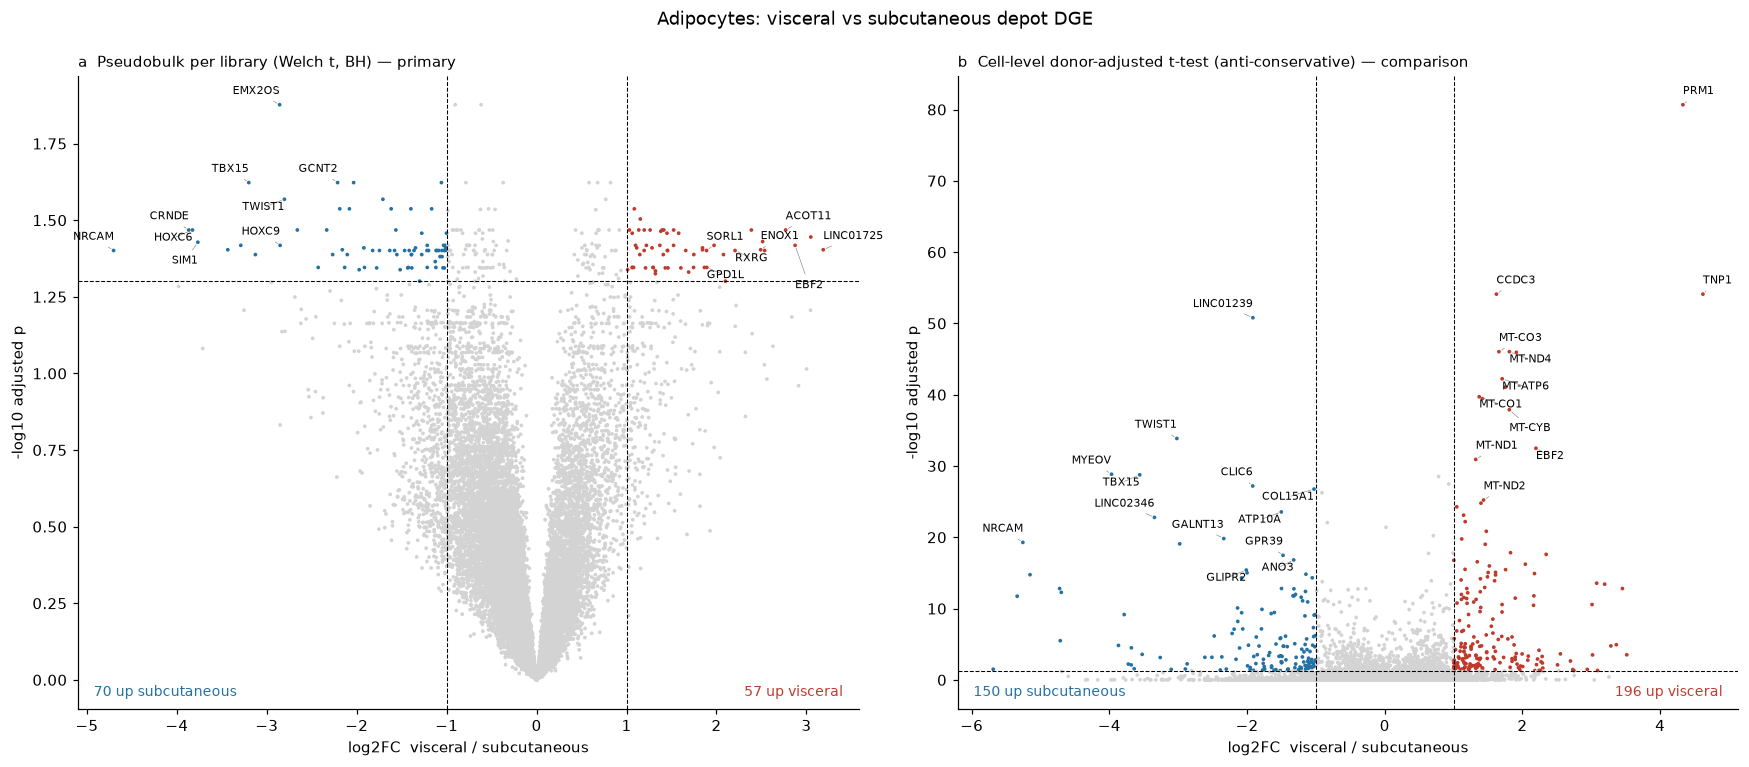

In [12]:
fig = wp.volcano(T)
fig.savefig(RESULTS / "DGE_adipocytes_depot_volcano.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
T.head(20)[["gene", "pb_log2FC_vis_vs_sq", "pb_padj", "paired_donors_concordant", "cell_log2FC_vis_vs_sq", "cell_padj", "pct_vis", "pct_sq"]].round(3)

,gene,pb_log2FC_vis_vs_sq,pb_padj,paired_donors_concordant,cell_log2FC_vis_vs_sq,cell_padj,pct_vis,pct_sq
11304,EMX2OS,-2.857,0.013,3,-2.870,0.006,0.015,0.121
13038,SMARCD1,-0.618,0.013,3,-0.697,0.160,0.107,0.165
360,SNHG12,-0.905,0.013,3,-0.851,0.569,0.036,0.065
6847,GCNT2,-2.213,0.024,3,-1.826,0.000,0.046,0.163
13120,LINC02381,-2.034,0.024,3,-2.160,0.001,0.022,0.110
16421,PLA2G15,-0.786,0.024,3,-0.632,0.655,0.053,0.086
21402,MBNL3,-1.058,0.024,3,-0.919,0.003,0.174,0.294
6292,ZNF608,0.679,0.024,3,0.764,0.006,0.533,0.405
1100,TBX15,-3.200,0.024,3,-3.559,0.000,0.045,0.414
5465,NAA15,-0.372,0.024,3,-0.287,0.550,0.397,0.439


**Reading.**
- Subcutaneous adipocytes carry a developmental positional-identity programme — HOXC6/HOXC8/HOXC9, TBX15, TWIST1, SIM1, EMX2OS — while visceral
  adipocytes are enriched for metabolic / lipid-handling genes (ACOT11, RXRG, EBF2, ENOX1). The direction holds in the paired donors for >90% of hits,
  so this is depot biology, not donor.
- The cell-level test returns ~3x more hits, but the extra signal is largely technical: mitochondrial transcripts and spermatid genes (PRM1, TNP1 —
  ambient RNA from the artefact cluster in visceral libraries) rise to the top. When depot is nested in donor, pseudobulk per library is the defensible route.